# Car Price Prediction — Machine Learning Pipeline

This notebook walks through a complete machine learning workflow for predicting car prices (**MSRP**) using the `Car.csv` dataset. It covers:

- **Exploratory Data Analysis (EDA)** — understanding the dataset's structure, distributions, and key trends
- **Data Cleaning** — handling missing values and standardizing messy categorical columns
- **Feature Engineering** — simplifying and encoding categorical variables
- **Model Training** — comparing multiple regression algorithms
- **Model Evaluation** — using R², MSE, and MAE to identify the best-performing model

## 1. Importing Libraries

We import all the libraries needed for data handling (`pandas`, `numpy`), visualization (`matplotlib`, `seaborn`), preprocessing (`StandardScaler`, `LabelEncoder`, `OneHotEncoder`), splitting data (`train_test_split`), regression models, and evaluation metrics (`r2_score`, `MAE`, `MSE`).

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
import warnings
warnings.filterwarnings("ignore")

## 2. Loading the Dataset

We load the `Car.csv` dataset into a pandas DataFrame and preview the first 3 rows to get a quick look at the columns and data types.

In [21]:
df = pd.read_csv("Car.csv")
df.head(3)

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350


## 3. Exploring 2-Door Cars

We filter the dataset to only include cars with **2 doors** and calculate the average, maximum, and minimum MSRP (price) for this subset. This gives us a quick sense of the price range for 2-door vehicles.

In [22]:
precious_car = df[df["Number of Doors"] == 2]

# Calculate average MSRP of 2-door cars
avg_price = precious_car["MSRP"].mean()
max_price = precious_car["MSRP"].max()
min_price = precious_car["MSRP"].min()
print("Max Price of 2-door cars: ", max_price)
print("Minimum Price of 2-door cars: ", min_price)
print("Average MSRP of 2-door cars:", avg_price)
df.rename(columns={"MSRP": "Price"}, inplace=True)

Max Price of 2-door cars:  2065902
Minimum Price of 2-door cars:  2000
Average MSRP of 2-door cars: 54556.08196202532


## 4. Identifying Premium Cars

From the 2-door cars, we extract the **premium segment** — cars priced above 100,000 (MSRP > 1 lac). We then count which car brands (`Make`) appear most frequently in this premium category and visualize the top 5 brands using a bar chart.

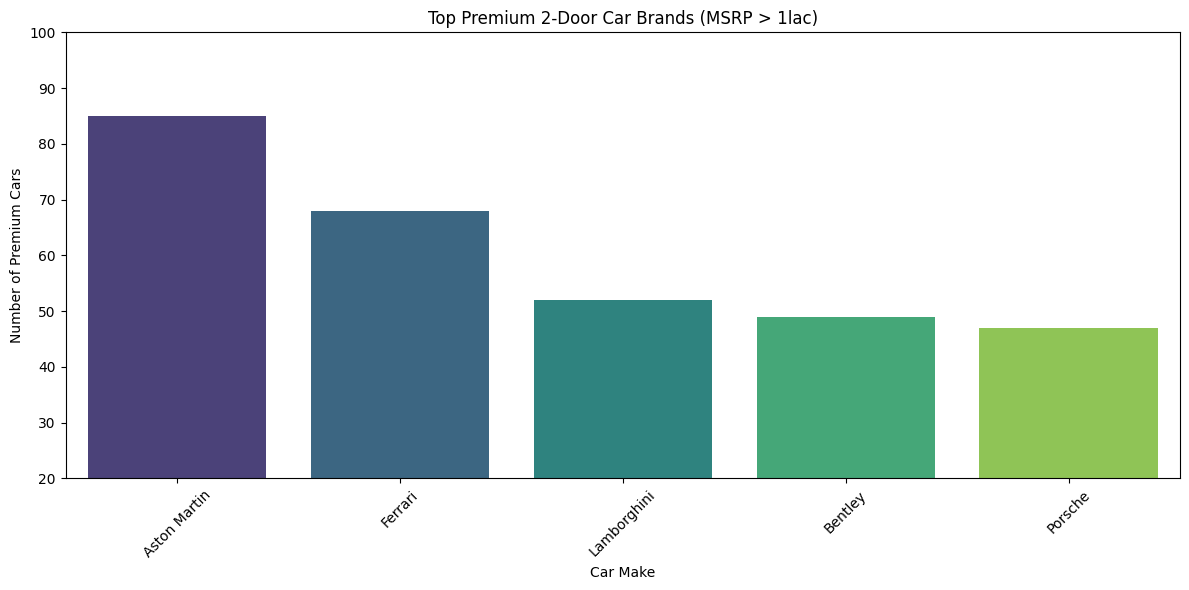

Make
Aston Martin     85
Ferrari          68
Lamborghini      52
Bentley          49
Porsche          47
Mercedes-Benz    47
Audi             25
Maserati         20
BMW              11
Rolls-Royce      11
Nissan            8
Dodge             7
McLaren           5
Spyker            3
Bugatti           3
Ford              2
Cadillac          2
Lexus             1
Acura             1
Name: count, dtype: int64

In [23]:

# Select premium 2-door cars (MSRP > 1 lac)
premium_cars = precious_car[precious_car["MSRP"] > 100000]


# Count of premium cars by Make (top 5)
make_counts = premium_cars["Make"].value_counts().reset_index()[:5]
make_counts.columns = ["Make", "Count"]


plt.figure(figsize=(12,6))
sns.barplot(x="Make", y="Count", data=make_counts, palette="viridis")
plt.title("Top Premium 2-Door Car Brands (MSRP > 1lac)")
plt.xlabel("Car Make")
plt.ylabel("Number of Premium Cars")
plt.ylim(20,100)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

premium_cars["Make"].value_counts()


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  str    
 1   Model              11914 non-null  str    
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  str    
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  str    
 7   Driven_Wheels      11914 non-null  str    
 8   Number of Doors    11908 non-null  float64
 9   Market Category    8172 non-null   str    
 10  Vehicle Size       11914 non-null  str    
 11  Vehicle Style      11914 non-null  str    
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  Price              11914 non-null  int64  
dtypes: float64(3), int64(5), str(8)
m

## 5. Checking for Missing Values

Before cleaning the data, we calculate the percentage of missing (null) values in each column and sort them in descending order. A heatmap is also plotted to visually highlight where the missing values are located across the dataset.

Market Category      31.4084
Engine HP             0.5792
Engine Cylinders      0.2518
Number of Doors       0.0504
Engine Fuel Type      0.0252
Make                  0.0000
Model                 0.0000
Year                  0.0000
Transmission Type     0.0000
Driven_Wheels         0.0000
Vehicle Size          0.0000
Vehicle Style         0.0000
highway MPG           0.0000
city mpg              0.0000
Popularity            0.0000
Price                 0.0000
dtype: float64


<Axes: >

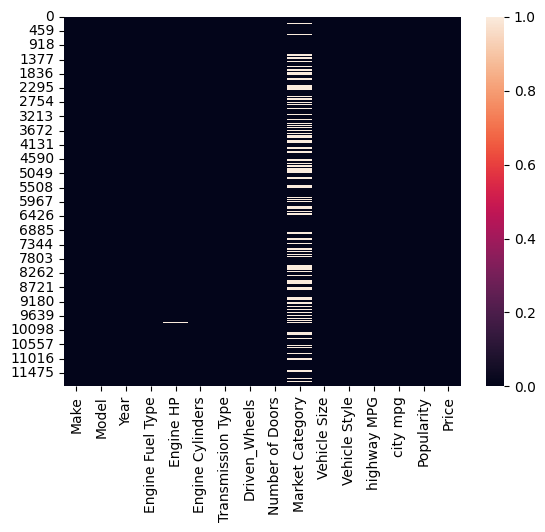

In [25]:
null_values = round(df.isnull().sum()/len(df)*100,4).sort_values(ascending=False)
print(null_values)
sns.heatmap(df.isnull())

## 6. Handling Missing Values

We fill in missing values using appropriate strategies:
- **Categorical columns** (`Market Category`, `Engine Fuel Type`) — filled with the **mode** (most frequent value).
- **Numerical columns** (`Engine HP`, `Engine Cylinders`, `Number of Doors`) — filled with the **mean** value of each column.

This ensures we don't lose valuable rows of data while keeping the dataset consistent for analysis and modeling.

In [26]:
object_col = ["Market Category", "Engine Fuel Type"]
for col in object_col:
    mode_value = df[col].mode()[0]
    df[col] = df[col].fillna(mode_value)

float_col = ["Engine HP", "Engine Cylinders", "Number of Doors"]
for col in float_col:
    mean_value = df[col].mean()
    df[col] = df[col].fillna(mean_value)
df.isnull().sum()



Make                 0
Model                0
Year                 0
Engine Fuel Type     0
Engine HP            0
Engine Cylinders     0
Transmission Type    0
Driven_Wheels        0
Number of Doors      0
Market Category      0
Vehicle Size         0
Vehicle Style        0
highway MPG          0
city mpg             0
Popularity           0
Price                0
dtype: int64

## 7. Analyzing Transmission Types

We look at the top 3 most common transmission types in the dataset and visualize their distribution using a pie chart, showing what percentage of cars fall into each transmission category.

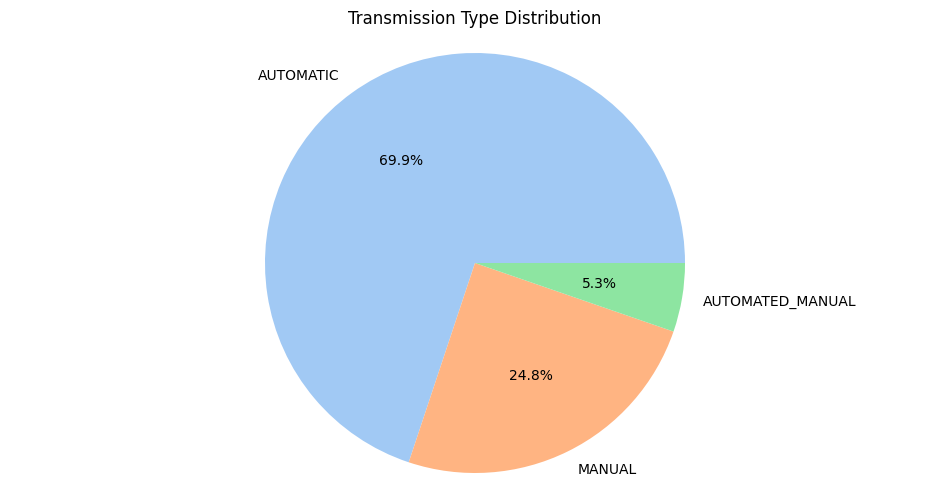

Transmission Type
AUTOMATIC           8266
MANUAL              2935
AUTOMATED_MANUAL     626
DIRECT_DRIVE          68
UNKNOWN               19
Name: count, dtype: int64

In [27]:
df.head()
transmission_counts = df["Transmission Type"].value_counts()[:3]

# Plot
plt.figure(figsize=(12, 6))
plt.pie(
    transmission_counts,
    labels=transmission_counts.index,
    autopct='%1.1f%%',
    colors=sns.color_palette('pastel')
)
plt.title("Transmission Type Distribution")
plt.axis('equal')  
plt.show()
df["Transmission Type"].value_counts()

## 8. Simplifying the 'Market Category' Column

The `Market Category` column originally contains multiple comma-separated tags per car (e.g., "Luxury, Performance"). To simplify this for analysis and modeling, we keep only the **first category** listed for each car, then visualize the new value counts as a bar chart.

Market Category
Crossover                                          4852
Flex Fuel                                           872
Luxury                                              855
Luxury,Performance                                  673
Hatchback                                           641
                                                   ... 
Crossover,Exotic,Luxury,High-Performance              1
Crossover,Exotic,Luxury,Performance                   1
Exotic,Luxury,High-Performance,Hybrid                 1
Flex Fuel,Factory Tuner,Luxury,High-Performance       1
Performance,Hybrid                                    1
Name: count, Length: 71, dtype: int64


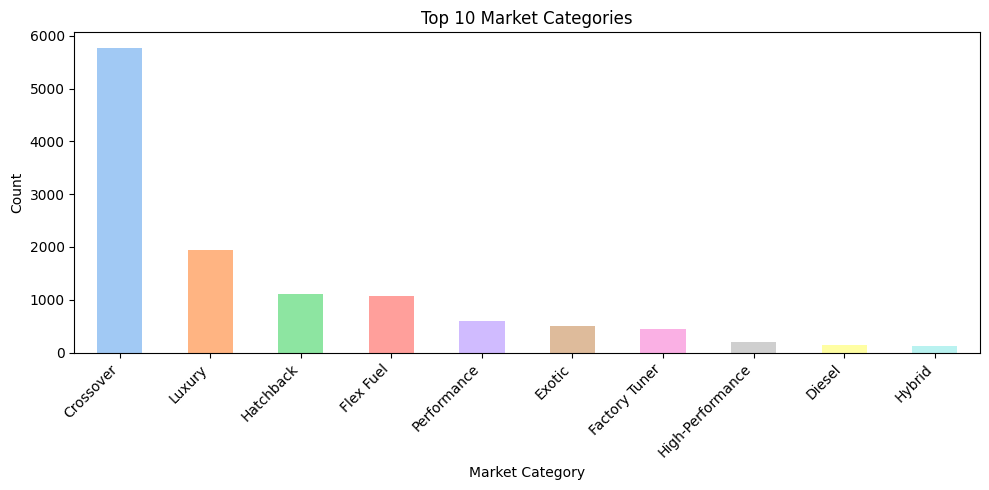

Market Category
Crossover           5776
Luxury              1937
Hatchback           1117
Flex Fuel           1080
Performance          602
Exotic               499
Factory Tuner        446
High-Performance     199
Diesel               135
Hybrid               123
Name: count, dtype: int64

In [28]:
print(df["Market Category"].value_counts())
df["Market Category"] = df["Market Category"].str.split(",").str.get(0)
top_categories = df["Market Category"].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_categories.plot(kind="bar", color=sns.color_palette("pastel"))
plt.title("Top 10 Market Categories")
plt.xlabel("Market Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
df["Market Category"].value_counts()

In [29]:
df.head()


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,Price
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Factory Tuner,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


## 9. Maximum Fuel Efficiency (MPG) by Vehicle Style

We group the data by `Vehicle Style` and find the **maximum highway MPG** and **city MPG** for each style, helping identify which vehicle types are most fuel-efficient.

In [30]:
df.groupby("Vehicle Style")[["highway MPG","city mpg"]].max()

,highway MPG,city mpg
Vehicle Style,,
2dr Hatchback,108,122
2dr SUV,30,22
4dr Hatchback,111,137
4dr SUV,74,78
Cargo Minivan,29,24
Cargo Van,20,15
Convertible,41,31
Convertible SUV,28,24
Coupe,41,31


## 10. Cleaning the 'Engine Fuel Type' Column

Similar to `Market Category`, the `Engine Fuel Type` column contains multi-word descriptions (e.g., "regular unleaded"). We simplify this by keeping only the **first word**, reducing the number of unique categories.

Engine Fuel Type
regular unleaded                                7175
premium unleaded (required)                     2009
premium unleaded (recommended)                  1523
flex-fuel (unleaded/E85)                         899
diesel                                           154
electric                                          66
flex-fuel (premium unleaded required/E85)         54
flex-fuel (premium unleaded recommended/E85)      26
flex-fuel (unleaded/natural gas)                   6
natural gas                                        2
Name: count, dtype: int64


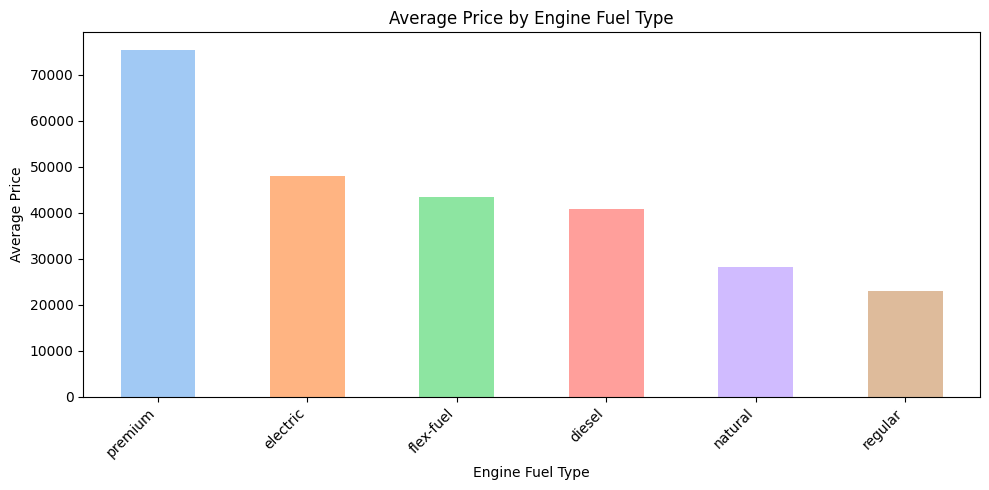

In [31]:
print(df["Engine Fuel Type"].value_counts())
df["Engine Fuel Type"] = df["Engine Fuel Type"].str.split(" ").str.get(0)

price = df.groupby("Engine Fuel Type")["Price"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
price.plot(kind="bar", color=sns.color_palette("pastel"))
plt.title("Average Price by Engine Fuel Type")
plt.xlabel("Engine Fuel Type")
plt.ylabel("Average Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 11. Standardizing 'Driven_Wheels' Values

We clean up the `Driven_Wheels` column by extracting the first word of each value and capitalizing it, giving us consistent, readable categories (e.g., "Front-wheel drive" → "Front").

In [32]:
print(df["Driven_Wheels"].unique())
df["Driven_Wheels"] = df["Driven_Wheels"].apply(lambda x: x.split()[0].capitalize())
df["Driven_Wheels"].value_counts()


<ArrowStringArray>
['rear wheel drive', 'front wheel drive', 'all wheel drive',
 'four wheel drive']
Length: 4, dtype: str


Driven_Wheels
Front    4787
Rear     3371
All      2353
Four     1403
Name: count, dtype: int64

## 12. Average Price by Engine Fuel Type

We visualize the **average MSRP** for cars grouped by their (cleaned) `Engine Fuel Type`, using a bar plot to compare price levels across different fuel types.

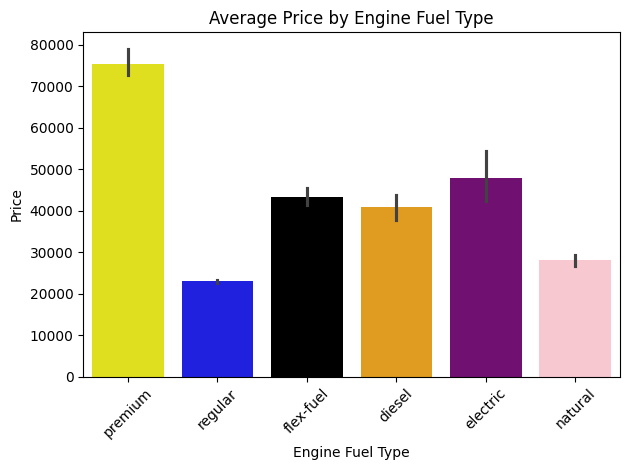

In [33]:
sns.barplot(
    data=df,
    x="Engine Fuel Type",
    y="Price",
    estimator='mean',
    palette=["yellow", "blue", "black", "orange","purple","pink"]  # Use palette instead of color
)

plt.xticks(rotation=45)
plt.title("Average Price by Engine Fuel Type")
plt.tight_layout()
plt.show()

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  str    
 1   Model              11914 non-null  str    
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11914 non-null  object 
 4   Engine HP          11914 non-null  float64
 5   Engine Cylinders   11914 non-null  float64
 6   Transmission Type  11914 non-null  str    
 7   Driven_Wheels      11914 non-null  str    
 8   Number of Doors    11914 non-null  float64
 9   Market Category    11914 non-null  object 
 10  Vehicle Size       11914 non-null  str    
 11  Vehicle Style      11914 non-null  str    
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  Price              11914 non-null  int64  
dtypes: float64(3), int64(5), object(2

## 13. Encoding Categorical Variables

Machine learning models require numerical input, so we convert all categorical (text) columns into numeric form using **Label Encoding**. The columns encoded are: `Make`, `Model`, `Engine Fuel Type`, `Transmission Type`, `Driven_Wheels`, `Market Category`, `Vehicle Size`, and `Vehicle Style`.

In [35]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import pandas as pd


Object_columns = [
    'Make', 'Model', 'Engine Fuel Type', 'Transmission Type',
    'Driven_Wheels', 'Market Category', 'Vehicle Size', 'Vehicle Style'
]


encoder = LabelEncoder()


for column in Object_columns:
    df[column] = encoder.fit_transform(df[[column]])
    
scaler = StandardScaler()
df[df.columns] = scaler.fit_transform(df[df.columns])

df.tail(3)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,Price
11911,-1.596919,1.636483,0.213164,-0.358818,0.464900,0.208729,-0.487387,-1.659471,0.640035,-0.889882,1.180202,-1.293007,-0.41043,-0.415387,-0.936965,0.166791
11912,-1.596919,1.636483,0.345101,-0.358818,0.464900,0.208729,-0.487387,-1.659471,0.640035,-0.889882,1.180202,-1.293007,-0.41043,-0.415387,-0.936965,0.171783
11913,0.121864,1.640196,-0.578453,0.615198,-0.260732,0.208729,-0.487387,0.215440,0.640035,1.509791,1.180202,1.148467,-0.07193,-0.304120,-1.036147,-0.192986


## 15. Splitting Features and Target

We separate the dataset into:
- **`X`** — all feature columns (everything except `MSRP`)
- **`y`** — the target variable we want to predict (`MSRP`, i.e., car price)

In [36]:
X = df.drop("Price", axis=1)
y = df["Price"]

## 16. Train-Test Split

We split the data into **80% training** and **20% testing** sets. The training set is used to fit the models, while the test set is used to evaluate how well they generalize to unseen data.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (9531, 15)
X_test shape: (2383, 15)
y_train shape: (9531,)
y_test shape: (2383,)


## 17. Comparing Multiple Regression Models

We train and evaluate **five different regression models** on the same training/test split:
1. Linear Regression
2. Ridge Regression
3. Decision Tree Regressor
4. Random Forest Regressor
5. K-Nearest Neighbors Regressor

For each model, we calculate the **R² score**, which tells us how well the model explains the variance in car prices (closer to 1.0 = better fit).

In [38]:


models = [
    LinearRegression(),
    Ridge(),  # Regularized linear regression
    DecisionTreeRegressor(),
    RandomForestRegressor(),
    KNeighborsRegressor()
]

model_names = [
    "Linear Regression",
    "Ridge Regression",
    "Decision Tree Regressor",
    "Random Forest Regressor",
    "K Neighbors Regressor"
]



model_score = []

for model, name in zip(models, model_names):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    model_score.append([name, r2])

results_df = pd.DataFrame(model_score, columns=["Model", "R2 Score"])
print(results_df)



                     Model  R2 Score
0        Linear Regression  0.584628
1         Ridge Regression  0.584647
2  Decision Tree Regressor  0.958607
3  Random Forest Regressor  0.974061
4    K Neighbors Regressor  0.927334


## 18. Identifying the Best Performing Model

We sort all models by their R² score in descending order and identify the model with the **highest R²**, indicating the best predictive performance for car price (MSRP).

In [39]:
best_model = sorted(model_score, key=lambda x: x[1], reverse=True)
print(f"Overall best model for predicting the MRSP IS : {best_model[0][0]}")
print(f"Best model R2 score: {best_model[0][1]}")

Overall best model for predicting the MRSP IS : Random Forest Regressor
Best model R2 score: 0.9740605753721905


## 19. Top 3 Models by R² Score

We extract the **top 3 models** based on R² score and display their scores as percentages for easier comparison.

In [40]:
top_three = best_model[:3]

# Separate model names and scores
top_three_models = [model[0] for model in top_three]
top_three_scores = [round(model[1], 4) for model in top_three]

# Print
# Format scores as percentages
formatted_scores = [f"{score * 100:.2f}%" for score in top_three_scores]

print(f"Top three models are {', '.join(top_three_models)},\nwith scores {formatted_scores}")



Top three models are Random Forest Regressor, Decision Tree Regressor, K Neighbors Regressor,
with scores ['97.41%', '95.86%', '92.73%']


## 20. Visualizing Top 3 Models

We create a pie chart to visually compare the R² scores (as percentages) of the top 3 performing models.

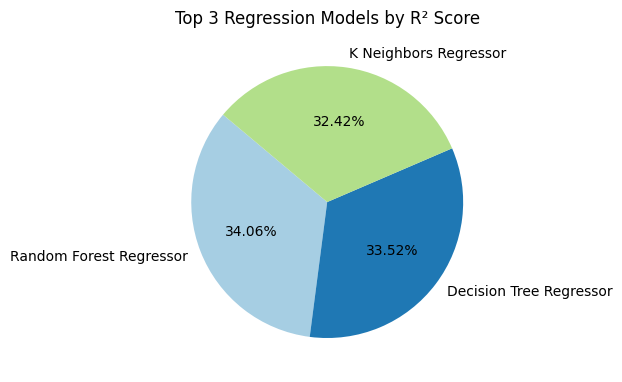

In [41]:
import matplotlib.pyplot as plt


plt.figure(figsize=(6, 6))
plt.pie(
    top_three_scores,                      # Values
    labels=top_three_models,              # Labels
    autopct='%1.2f%%',                    # Show percentage
    startangle=140,                       # Rotate for better view
    colors=plt.cm.Paired.colors[:3]       # Optional color palette
)
plt.title('Top 3 Regression Models by R² Score')
plt.tight_layout()
plt.show()


## 21. Evaluating Models with Error Metrics

Beyond R², we also calculate **Mean Squared Error (MSE)** and **Mean Absolute Error (MAE)** for each model. These metrics measure the average prediction error in absolute terms — lower values indicate better performance.

In [42]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

metrics_result = []

for model, name in zip(models, model_names):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    metrics_result.append([name, round(mse, 4), round(mae, 4), round(rmse, 4)])

# Create DataFrame to display results
metrics_df = pd.DataFrame(metrics_result, columns=["Model", "MSE", "MAE", "RMSE"])
print(metrics_df)


                     Model     MSE     MAE    RMSE
0        Linear Regression  0.2740  0.3309  0.5235
1         Ridge Regression  0.2740  0.3308  0.5235
2  Decision Tree Regressor  0.0252  0.0546  0.1588
3  Random Forest Regressor  0.0184  0.0515  0.1356
4    K Neighbors Regressor  0.0479  0.0767  0.2190


## 22. Best and Worst Model by MSE

Finally, we identify the **minimum and maximum MSE** values across all models, showing the range of prediction error — the model with the lowest MSE made the most accurate predictions overall.

In [43]:
minimum_mse = np.min(metrics_df['MSE'])
maximum_mse = np.max(metrics_df['MSE'])
print('Minimum MSE:', minimum_mse)
print('Maximum MSE:', maximum_mse)


Minimum MSE: 0.0184
Maximum MSE: 0.274
